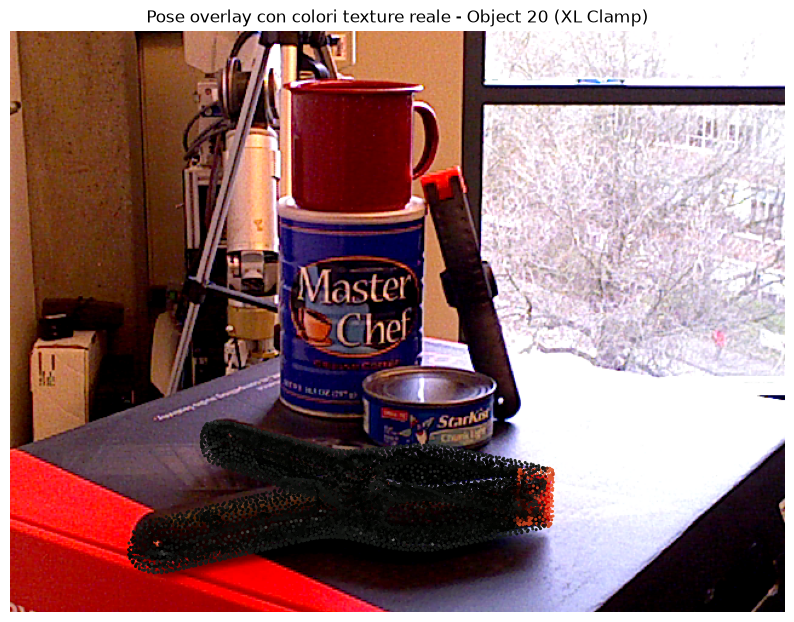

In [38]:
# CHOOSE A SINGLE IMAGE. IN THIS CASE FROM THE DATASET YCBV (Scene 48, Image 47, Object 20 - XL Clamp)

import json
import numpy as np
import trimesh
import cv2
import matplotlib.pyplot as plt
import torch
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["HYDRA_FULL_ERROR"] = "1" # Debug

rgb_path = "/data/riccardop02/datasets/ycbv/test/000048/rgb/000047.png"
mask_path = "/data/riccardop02/datasets/ycbv/test/000048/mask_visib/000001_000004.png"
scene_camera_path = "/data/riccardop02/datasets/ycbv/test/000048/scene_camera.json"
model_path = "/data/riccardop02/datasets/ycbv/models/obj_000020.ply"

Pose = {
    "cam_R_m2c": [-0.9993032187000758, -0.03468586763469483, 0.013799769394337228,
                   0.02273746658654025, -0.27237133848523803, 0.9619233928797483,
                  -0.02960648331060263, 0.9615662504172701, 0.2729703664836574],
    "cam_t_m2c": [-20.983454465364908, 85.55142809136696, 684.4252367092936]
}

# --- Intrinseci ---
with open(scene_camera_path, "r") as f:
    scene_camera = json.load(f)
K = np.array(scene_camera["47"]["cam_K"]).reshape(3, 3)

# --- Carica mesh (texture già embedded automaticamente da trimesh) ---
mesh = trimesh.load(model_path, process=False)
vertices = np.array(mesh.vertices)               # (10064, 3)
uv = np.array(mesh.visual.uv)                     # (10064, 2)

# --- Usa la texture già caricata da trimesh, non ricaricarla da file ---
texture_img = np.array(mesh.visual.material.image.convert("RGB"))  # (4096, 4096, 3)
tex_h, tex_w = texture_img.shape[:2]

# --- Converti UV in coordinate pixel della texture ---
u_px = np.clip((uv[:, 0] * (tex_w - 1)).astype(int), 0, tex_w - 1)
v_px = np.clip(((1 - uv[:, 1]) * (tex_h - 1)).astype(int), 0, tex_h - 1)  # flip verticale

vertex_colors = texture_img[v_px, u_px] / 255.0   # (10064, 3), in [0,1]

# --- Trasforma i vertici in camera coords e proietta ---
R = np.array(Pose["cam_R_m2c"]).reshape(3, 3)
t = np.array(Pose["cam_t_m2c"]).reshape(3, 1)

points_cam = (R @ vertices.T) + t
points_img_h = K @ points_cam
points_img = (points_img_h[:2, :] / points_img_h[2, :]).T

# --- Carica RGB della scena ---
rgb = cv2.imread(rgb_path)
rgb_rgb = cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB)
h, w = rgb.shape[:2]

valid = (points_img[:, 0] >= 0) & (points_img[:, 0] < w) & \
        (points_img[:, 1] >= 0) & (points_img[:, 1] < h)

# --- Plot con i colori reali della texture ---
plt.figure(figsize=(10, 8))
plt.imshow(rgb_rgb)
plt.scatter(points_img[valid, 0], points_img[valid, 1],
            s=1.5, c=vertex_colors[valid], alpha=0.9)
plt.title("Pose overlay con colori texture reale - Object 20 (XL Clamp)")
plt.axis('off')
plt.show()

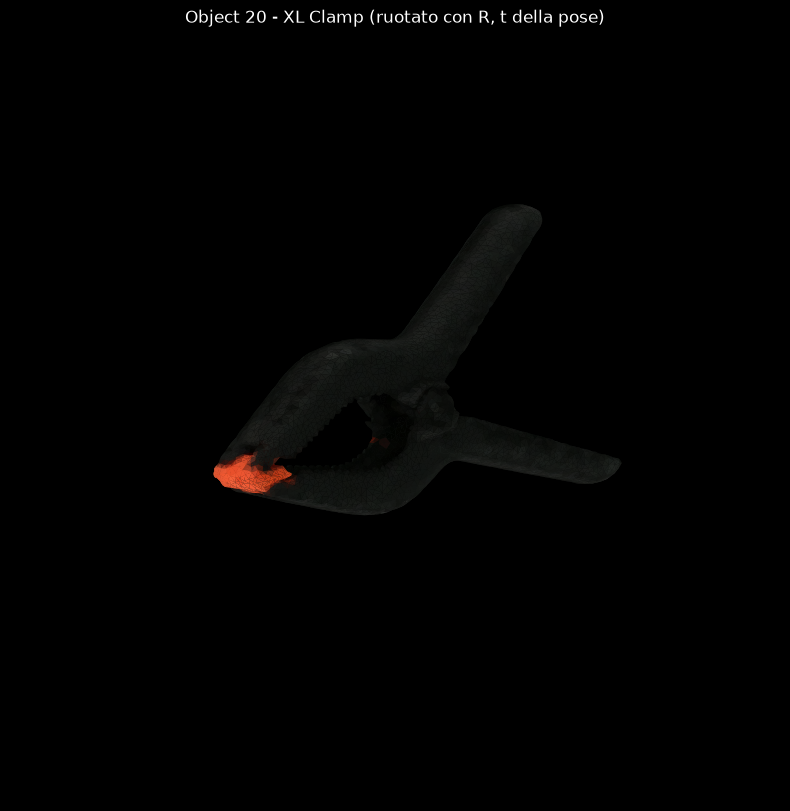

In [39]:
import numpy as np
import trimesh
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

model_path = "/data/riccardop02/datasets/ycbv/models/obj_000020.ply"

# --- Carica mesh con texture ---
mesh = trimesh.load(model_path, process=False)
vertices = np.array(mesh.vertices)      # (N, 3), coordinate originali nel model frame
faces = mesh.faces                       # (F, 3)
uv = np.array(mesh.visual.uv)            # (N, 2)

texture_img = np.array(mesh.visual.material.image.convert("RGB"))
tex_h, tex_w = texture_img.shape[:2]

u_px = np.clip((uv[:, 0] * (tex_w - 1)).astype(int), 0, tex_w - 1)
v_px = np.clip(((1 - uv[:, 1]) * (tex_h - 1)).astype(int), 0, tex_h - 1)
vertex_colors = texture_img[v_px, u_px] / 255.0   # (N, 3)

# --- Applica R e t ai vertici (portali in camera frame) ---
R = np.array(Pose["cam_R_m2c"]).reshape(3, 3)
t = np.array(Pose["cam_t_m2c"]).reshape(3, 1)

vertices_cam = (R @ vertices.T + t).T   # (N, 3), ora ruotati/traslati come in camera frame

# --- Colore di ogni faccia = media dei 3 vertici ---
face_colors = vertex_colors[faces].mean(axis=1)   # (F, 3)

# --- Triangoli 3D con i vertici RUOTATI ---
triangles_3d = vertices_cam[faces]                 # (F, 3, 3)

# --- Plot 3D con sfondo nero ---
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection='3d')
fig.patch.set_facecolor('black')
ax.set_facecolor('black')

poly = Poly3DCollection(triangles_3d, facecolors=face_colors, edgecolors='none')
ax.add_collection3d(poly)

max_range = (vertices_cam.max(axis=0) - vertices_cam.min(axis=0)).max() / 2.0
mid = vertices_cam.mean(axis=0)
ax.set_xlim(mid[0] - max_range, mid[0] + max_range)
ax.set_ylim(mid[1] - max_range, mid[1] + max_range)
ax.set_zlim(mid[2] - max_range, mid[2] + max_range)

ax.set_axis_off()
ax.view_init(elev=20, azim=45)

plt.title("Object 20 - XL Clamp (ruotato con R, t della pose)", color='white')
plt.show()

In [40]:
# Import utilities for the 3D

def load_ycbv_mesh(model_path: str) -> trimesh.Trimesh:
    """Equivalente di load_gso_mesh, ma per un singolo file .ply YCB-V con texture embedded."""
    mesh = trimesh.load(model_path, process=False)
    if not isinstance(mesh, trimesh.Trimesh):
        raise ValueError(f"Expected a single mesh, got {type(mesh)}")
    return mesh


def sample_pointcloud_with_color(mesh: trimesh.Trimesh, n_points: int) -> np.ndarray:
    """
    Campiona n_points sulla superficie della mesh e assegna il colore
    interpolando la UV map sulla texture.
    Ritorna (n_points, 6): xyz grezzo + rgb in [0, 255].
    """
    # Campiona punti sulla superficie; face_idx dice da quale triangolo viene ogni punto
    points, face_idx = trimesh.sample.sample_surface(mesh, n_points)

    # Coordinate baricentriche di ogni punto rispetto al suo triangolo
    triangles = mesh.triangles[face_idx]              # (n_points, 3, 3)
    bary = trimesh.triangles.points_to_barycentric(triangles, points)  # (n_points, 3)

    # UV dei 3 vertici di ogni triangolo campionato
    uv_all = mesh.visual.uv                            # (N_vertices, 2)
    face_uv = uv_all[mesh.faces[face_idx]]              # (n_points, 3, 2)

    # Interpola la UV nel punto usando le coordinate baricentriche
    point_uv = np.einsum('ij,ijk->ik', bary, face_uv)   # (n_points, 2)

    # Campiona la texture in quelle coordinate UV
    texture_img = np.array(mesh.visual.material.image.convert("RGB"))
    tex_h, tex_w = texture_img.shape[:2]

    u_px = np.clip((point_uv[:, 0] * (tex_w - 1)).astype(int), 0, tex_w - 1)
    v_px = np.clip(((1 - point_uv[:, 1]) * (tex_h - 1)).astype(int), 0, tex_h - 1)

    colors = texture_img[v_px, u_px].astype(np.float32)  # (n_points, 3), in [0, 255]

    return np.concatenate([points, colors], axis=-1).astype(np.float32)  # (n_points, 6)


def normalize_pointcloud(pc: np.ndarray) -> np.ndarray:
    """
    pc: (N, 6) con xyz grezzo e rgb in [0, 255].
    Ritorna (N, 6) con xyz in sfera unitaria e rgb in [-1, 1].
    """
    xyz = pc[:, :3].copy()
    rgb = pc[:, 3:].copy()

    centroid = xyz.mean(axis=0, keepdims=True)
    xyz = xyz - centroid
    scale = np.max(np.linalg.norm(xyz, axis=1))
    if scale > 0:
        xyz = xyz / scale

    rgb = (rgb / 255.0 - 0.5) / 0.5

    return np.concatenate([xyz, rgb], axis=-1).astype(np.float32)


def process_single_object(model_path: str, encoder3d, n_points: int, device: torch.device):
    """Versione single-object di process_model, per test rapido su Object 20."""
    mesh = load_ycbv_mesh(model_path)
    pc = sample_pointcloud_with_color(mesh, n_points)
    pc = normalize_pointcloud(pc)

    pc_tensor = torch.from_numpy(pc).unsqueeze(0).to(device)  # (1, N, 6)

    with torch.no_grad():
        feats, centers = encoder3d.extractFeatures(pc_tensor)

    return feats.squeeze(0).cpu().numpy(), centers.squeeze(0).cpu().numpy()

In [5]:
# Initialization of the encoder3d and then of the JEPA
import logging
import torch
import hydra
import sys
from hydra import compose, initialize
from omegaconf import OmegaConf
sys.path.insert(0, "/home/riccardop02/JEPA")

logging.basicConfig(level=logging.INFO)
log = logging.getLogger(__name__)

# --- Config ---
with initialize(version_base=None, config_path="../../configs"):
    cfg = compose(config_name="config")

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# Only for the UNI3D
cfg.encoder3d['ckpt_path'] = "/home/riccardop02/JEPA/weights/model.pt"

# --- Istanzia i modelli ---
encoder2d = hydra.utils.instantiate(cfg.encoder2d)
encoder3d = hydra.utils.instantiate(cfg.encoder3d)
encoder2d.to(device)
encoder3d.to(device)
log.info("Dino Initialized...")
log.info(f"Encoder2d: {type(encoder2d)}, output_dim: {encoder2d.output_dim}, "
          f"layers: {encoder2d.layers}, token: {encoder2d.token}")
log.info(f"Encoder3d: {type(encoder3d)}, output_dim: {encoder3d.output_dim}")

predictor = hydra.utils.instantiate(
    cfg.Predictor,
    context_dim=encoder3d.output_dim[0][-1],
    output_dim=encoder2d.output_dim[-1]
)
predictor.to(device)

# predictor appena inizializzato (pesi random), per confronto/test strutturale
predictor_init = hydra.utils.instantiate(
    cfg.Predictor, context_dim=encoder3d.output_dim[0][-1], output_dim=encoder2d.output_dim[-1]
).to(device)
predictor_init.eval()

# --- Carica checkpoint ---
PATH_CHECK = '/experiments/riccardop02/outputs/2026-09-01/04-39-34/checkpoints/best.pt' 
checkpoint = torch.load(PATH_CHECK, map_location=device)

encoder2d.load_state_dict(checkpoint["models"]['encoder2d'])
predictor.load_state_dict(checkpoint["models"]['predictor'])
encoder3d.load_state_dict(checkpoint["models"]['encoder3d'])

encoder2d.eval()
predictor.eval()
encoder3d.eval()
log.info(f"Checkpoint loaded from {PATH_CHECK}")

# --- Test su singolo oggetto ---
model_path = "/data/riccardop02/datasets/ycbv/models/obj_000020.ply"
#feats3d, centers= process_single_object(model_path, encoder3d, n_points=8192, device=device)

#log.info(f"3D features: {feats3d.shape}, centers: {centers.shape}")

INFO:httpx:HTTP Request: HEAD https://huggingface.co/facebook/dinov2-base/resolve/main/processor_config.json "HTTP/1.1 404 Not Found"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/facebook/dinov2-base/resolve/main/preprocessor_config.json "HTTP/1.1 307 Temporary Redirect"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/facebook/dinov2-base/f9e44c814b77203eaa57a6bdbbd535f21ede1415/preprocessor_config.json "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/facebook/dinov2-base/resolve/main/processor_config.json "HTTP/1.1 404 Not Found"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/facebook/dinov2-base/resolve/main/preprocessor_config.json "HTTP/1.1 307 Temporary Redirect"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/facebook/dinov2-base/f9e44c814b77203eaa57a6bdbbd535f21ede1415/preprocessor_config.json "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/facebook/dinov2-base/

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

INFO:root:Uni3D constructed, loading Uni3D weights from /home/riccardop02/JEPA/weights/model.pt ...
INFO:__main__:Dino Initialized...
INFO:__main__:Encoder2d: <class 'src.models.encoder2d.DINOv2.DINOv2'>, output_dim: torch.Size([256, 768]), layers: [9], token: PatchToken
INFO:__main__:Encoder3d: <class 'src.models.encoder3d.Uni3D.Uni3DEncoder'>, output_dim: ((1, 512, 768), (1, 512, 3))
INFO:root:RayCrossAttnPredictor initialized (depth=6, FourierBands=6)
INFO:root:RayCrossAttnPredictor initialized (depth=6, FourierBands=6)
/tmp/ipykernel_2752406/1750610621.py:47: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`.

In [42]:
import json
import numpy as np
import torch
import torch.nn.functional as F
import cv2
from PIL import Image
from scipy.spatial.transform import Rotation

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

rgb_path = "/data/riccardop02/datasets/ycbv/test/000048/rgb/000047.png"
mask_path = "/data/riccardop02/datasets/ycbv/test/000048/mask_visib/000001_000004.png"
scene_camera_path = "/data/riccardop02/datasets/ycbv/test/000048/scene_camera.json"

GRID_SIZE = 16
PATCH_SIZE = 14
OUT_SIZE = GRID_SIZE * PATCH_SIZE  # 224
CROP_RATIO = 1.2  # stesso valore di default del dataset GSO

# --- K originale (intrinseci dell'immagine intera, non ancora croppata) ---
with open(scene_camera_path, "r") as f:
    scene_camera = json.load(f)
K_orig = np.array(scene_camera["47"]["cam_K"]).reshape(3, 3).astype(np.float32)

# --- R dalla pose ---
R_np = np.array(Pose["cam_R_m2c"]).reshape(3, 3).astype(np.float32)

# --- Carica immagine intera e maschera (stessa risoluzione, non ancora croppate) ---
img_pil = Image.open(rgb_path).convert("RGB")
mask_np_full = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
mask_bool = mask_np_full > 0

# --- Calcola il crop box dalla maschera, ESATTAMENTE come _get_crop_box del dataset ---
def get_crop_box(mask_bool, crop_ratio):
    ys, xs = np.where(mask_bool)
    if len(xs) == 0:
        return None
    x0, x1 = xs.min(), xs.max()
    y0, y1 = ys.min(), ys.max()
    cx, cy = (x0 + x1) / 2.0, (y0 + y1) / 2.0
    half = max(x1 - x0, y1 - y0) * crop_ratio / 2.0
    return (int(round(cx - half)), int(round(cy - half)),
            int(round(cx + half)), int(round(cy + half)))

box = get_crop_box(mask_bool, CROP_RATIO)
if box is None:
    raise ValueError("Maschera vuota, impossibile calcolare il crop box.")

# --- Croppa immagine e maschera sul box (identico a _expand_objects) ---
img_cropped = img_pil.crop(box).resize((OUT_SIZE, OUT_SIZE), Image.BICUBIC)

mask_pil_full = Image.fromarray(mask_bool.astype(np.uint8) * 255)
mask_cropped_pil = mask_pil_full.crop(box)
mask_grid_pil = mask_cropped_pil.resize((GRID_SIZE, GRID_SIZE), Image.BOX)

# --- Normalizza immagine (stesse mean/std del dataset) ---
import torchvision.transforms.functional as TF
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)

img_t = TF.normalize(TF.to_tensor(img_cropped), MEAN, STD).unsqueeze(0).to(device)  # (1, 3, 224, 224)
mask_tokens_t = TF.to_tensor(mask_grid_pil).reshape(1, -1).to(device)  # (1, 256)

# --- Ricalcola K rispetto al CROP, non all'immagine intera ---
xmin, ymin, xmax, ymax = box
crop_w, crop_h = xmax - xmin, ymax - ymin

scale_x = OUT_SIZE / float(crop_w)
scale_y = OUT_SIZE / float(crop_h)

K_crop = K_orig.copy()
K_crop[0, 0] = K_orig[0, 0] * scale_x
K_crop[1, 1] = K_orig[1, 1] * scale_y
K_crop[0, 2] = (K_orig[0, 2] - xmin) * scale_x
K_crop[1, 2] = (K_orig[1, 2] - ymin) * scale_y

K_t = torch.from_numpy(K_crop).unsqueeze(0).float().to(device)  # (1, 3, 3)
rot_t = torch.from_numpy(R_np).unsqueeze(0).float().to(device)   # (1, 3, 3)

# Alias per compatibilità con la cella 2 di prima
mask_t = mask_tokens_t

print("img_t:", img_t.shape)
print("mask_t:", mask_t.shape, "min/max:", mask_t.min().item(), mask_t.max().item())
print("rot_t:", rot_t.shape)
print("K_t:", K_t.shape)
print("crop box:", box)

img_t: torch.Size([1, 3, 224, 224])
mask_t: torch.Size([1, 256]) min/max: 0.0 1.0
rot_t: torch.Size([1, 3, 3])
K_t: torch.Size([1, 3, 3])
crop box: (57, 186, 476, 605)


In [43]:
def generate_rays(K: torch.Tensor, R: torch.Tensor, grid_size: int = 16, patch_size: int = 14) -> torch.Tensor:
    B = K.shape[0]
    device = K.device

    y = torch.arange(grid_size, device=device, dtype=torch.float32)
    x = torch.arange(grid_size, device=device, dtype=torch.float32)
    grid_y, grid_x = torch.meshgrid(y, x, indexing='ij')
    u = grid_x * patch_size + (patch_size / 2.0)
    v = grid_y * patch_size + (patch_size / 2.0)
    uv1 = torch.stack([u, v, torch.ones_like(u)], dim=-1).reshape(-1, 3)
    uv1 = uv1.unsqueeze(0).expand(B, -1, -1)  # (B, 256, 3)

    K_inv = torch.linalg.inv(K)
    d_c = torch.bmm(uv1, K_inv.transpose(1, 2))

    R_inv = R.transpose(1, 2)
    d_o = torch.bmm(d_c, R_inv.transpose(1, 2))  # Object space rays

    return F.normalize(d_o, p=2, dim=-1)

def masked_l1_per_sample(pred_tensor, targ_tensor, mask_tensor):
    """Restituisce la L1 mascherata per ogni elemento del batch: shape (B,)"""
    err = F.l1_loss(pred_tensor, targ_tensor, reduction='none').mean(dim=-1)  # (B, N)
    valid = mask_tensor.float()
    return (err * valid).sum(dim=1) / valid.sum(dim=1).clamp(min=1.0)

In [44]:
import torch
import torch.nn.functional as F
import numpy as np
from scipy.spatial.transform import Rotation

import numpy as np

def rotation_geodesic_distance_deg(R1: np.ndarray, R2: np.ndarray) -> float:
    """Distanza angolare (gradi) tra due matrici di rotazione 3x3."""
    R_rel = R1 @ R2.T
    trace = np.clip((np.trace(R_rel) - 1.0) / 2.0, -1.0, 1.0)
    return np.degrees(np.arccos(trace))




B = img_t.shape[0]
assert B == 1, "Questo blocco assume B=1 (singolo oggetto/immagine)"

context_t = torch.from_numpy(feats3d).float().to(device) if isinstance(feats3d, np.ndarray) else feats3d.float().to(device)
centers_t = torch.from_numpy(centers).float().to(device) if isinstance(centers, np.ndarray) else centers.float().to(device)
if context_t.dim() == 2:
    context_t = context_t.unsqueeze(0)
if centers_t.dim() == 2:
    centers_t = centers_t.unsqueeze(0)

valid_mask = mask_t > 0.5

# --- Target e predizione con rotazione corretta (riferimento) ---
ray_dirs_correct = generate_rays(K_t, rot_t)
with torch.no_grad():
    target = encoder2d(img_t)
    pred_correct = predictor(
        ray_queries=ray_dirs_correct,
        context_features=context_t,
        context_centers=centers_t,
        mask=mask_t
    )
err_correct = masked_l1_per_sample(pred_correct, target, valid_mask)

# --- 2000 rotazioni random ---
N_SAMPLES = 2000
random_rot_np = Rotation.random(N_SAMPLES).as_matrix()          # (2000, 3, 3)
random_rot_t = torch.tensor(random_rot_np, dtype=torch.float32, device=device)

# Espandi K, context, centers, mask per batch
K_batch = K_t.expand(N_SAMPLES, -1, -1)
context_batch = context_t.expand(N_SAMPLES, -1, -1)
centers_batch = centers_t.expand(N_SAMPLES, -1, -1)
mask_batch = mask_t.expand(N_SAMPLES, -1)
target_batch = target.expand(N_SAMPLES, -1, -1)
valid_mask_batch = valid_mask.expand(N_SAMPLES, -1)

ray_dirs_random_batch = generate_rays(K_batch, random_rot_t)

with torch.no_grad():
    pred_random_batch = predictor(
        ray_queries=ray_dirs_random_batch,
        context_features=context_batch,
        context_centers=centers_batch,
        mask=mask_batch
    )

err_random_batch = masked_l1_per_sample(pred_random_batch, target_batch, valid_mask_batch)  # (2000,)

# --- Top-5 rotazioni con errore minimo (argmin) ---
K_TOP = 5
topk_errs, topk_idx = torch.topk(err_random_batch, K_TOP, largest=False)
topk_idx = topk_idx.cpu().numpy()
topk_errs = topk_errs.cpu().numpy()
topk_rotations = random_rot_np[topk_idx]  # (5, 3, 3)

# --- Estrazione della GT come array numpy ---
rot_correct_np = rot_t.squeeze(0).cpu().numpy()

# --- Ricerca della rotazione random geometricamente più vicina alla GT ---
all_dists = [rotation_geodesic_distance_deg(r, rot_correct_np) for r in random_rot_np]
min_dist_idx = np.argmin(all_dists)
min_dist_val = all_dists[min_dist_idx]
min_dist_l1 = err_random_batch[min_dist_idx].item()

# --- STAMPE ---
print(f"L1 con rotazione corretta (GT): {err_correct.item():.5f}\n")

print(f"--- ANALISI DEL CAMPIONE RANDOM PIÙ VICINO ALLA GT ---")
print(f"Distanza minima assoluta tra le {N_SAMPLES} random e la GT: {min_dist_val:.2f}°")
print(f"L1 err associato a questa rotazione: {min_dist_l1:.5f}\n")

print(f"--- TOP {K_TOP} ROTAZIONI CON L1 MINORE ---")
print(f"{'Rank':<6}{'L1 err':<12}{'Dist. da GT (°)':<18}")
print("-" * 36)
for rank, (idx, e) in enumerate(zip(topk_idx, topk_errs)):
    dist_deg = rotation_geodesic_distance_deg(topk_rotations[rank], rot_correct_np)
    print(f"{rank+1:<6}{e:<12.5f}{dist_deg:<18.2f}")

L1 con rotazione corretta (GT): 0.02405

--- ANALISI DEL CAMPIONE RANDOM PIÙ VICINO ALLA GT ---
Distanza minima assoluta tra le 2000 random e la GT: 9.32°
L1 err associato a questa rotazione: 0.02407

--- TOP 5 ROTAZIONI CON L1 MINORE ---
Rank  L1 err      Dist. da GT (°)   
------------------------------------
1     0.02299     23.49             
2     0.02301     176.39            
3     0.02304     164.19            
4     0.02307     170.33            
5     0.02308     157.74            


In [6]:
import torch
import numpy as np
from omegaconf import OmegaConf

# Riusa il 'dataset' già istanziato in precedenza (hydra.utils.instantiate(cfg.data, ..., split="val"))
# Se non è più in memoria, ricrealo:
dataset = hydra.utils.instantiate(cfg.data, dataset_source=cfg.gso.root, split="val")

loader_single = torch.utils.data.DataLoader(dataset, batch_size=1, num_workers=0)
sample_iter = iter(loader_single)

INFO:root:[GSOMegaposeDataset:val] 105/1050 shards, type: (remote)


In [17]:
import matplotlib.pyplot as plt
# Prendi un sample (puoi rieseguire questa cella per ottenerne un altro a caso)
batch = next(sample_iter)

img_t = batch['image'].to(device)          # (1, 3, 224, 224), già normalizzata
mask_t = batch['mask_tokens'].to(device)    # (1, 256)
context_t = batch['context_3d'].to(device)  # (1, N, context_dim)
centers_t = batch['center_3d'].to(device)   # (1, N, 3)
rot_t = batch['rot_matrix'].to(device)      # (1, 3, 3)
K_t = batch['K'].to(device)                 # (1, 3, 3)

model_name = batch['model_name'][0]
print("Oggetto GSO campionato:", model_name)
print("img_t:", img_t.shape, "mask_t:", mask_t.shape, "context_t:", context_t.shape, "K_t:", K_t.shape)

# --- Per la visualizzazione, serve anche l'immagine "de-normalizzata" (per mostrarla come RGB) ---
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)
img_denorm = (img_t * STD + MEAN).clamp(0, 1)
bg_img_gso = (img_denorm.squeeze(0).permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)  # (224, 224, 3)

plt.imshow(bg_img_gso)
plt.title(f"GSO sample: {model_name}")
plt.axis('off')
plt.show()

StopIteration: 

In [64]:
B = img_t.shape[0]
assert B == 1

valid_mask = mask_t > 0.5

# --- Target e predizione con rotazione corretta ---
ray_dirs_correct = generate_rays(K_t, rot_t)
with torch.no_grad():
    target_gso = encoder2d(img_t)
    pred_correct_gso = predictor(
        ray_queries=ray_dirs_correct,
        context_features=context_t,
        context_centers=centers_t,
        mask=mask_t
    )
err_correct_gso = masked_l1_per_sample(pred_correct_gso, target_gso, valid_mask)

# --- 2000 rotazioni random ---
N_SAMPLES = 2000
random_rot_np_gso = Rotation.random(N_SAMPLES).as_matrix()
random_rot_t_gso = torch.tensor(random_rot_np_gso, dtype=torch.float32, device=device)

K_batch = K_t.expand(N_SAMPLES, -1, -1)
context_batch = context_t.expand(N_SAMPLES, -1, -1)
centers_batch = centers_t.expand(N_SAMPLES, -1, -1)
mask_batch = mask_t.expand(N_SAMPLES, -1)
target_batch = target_gso.expand(N_SAMPLES, -1, -1)
valid_mask_batch = valid_mask.expand(N_SAMPLES, -1)

ray_dirs_random_batch_gso = generate_rays(K_batch, random_rot_t_gso)

with torch.no_grad():
    pred_random_batch_gso = predictor(
        ray_queries=ray_dirs_random_batch_gso,
        context_features=context_batch,
        context_centers=centers_batch,
        mask=mask_batch
    )

err_random_batch_gso = masked_l1_per_sample(pred_random_batch_gso, target_batch, valid_mask_batch)

# --- Ricerca delle 5 rotazioni con Errore L1 minore ---
K_TOP = 5
topk_errs_gso, topk_idx_gso = torch.topk(err_random_batch_gso, K_TOP, largest=False)
topk_idx_gso = topk_idx_gso.cpu().numpy()
topk_errs_gso = topk_errs_gso.cpu().numpy()
topk_rotations_gso = random_rot_np_gso[topk_idx_gso]

rot_correct_np_gso = rot_t.squeeze(0).cpu().numpy()

# --- Ricerca della rotazione geometricamente più vicina alla GT ---
# Calcoliamo tutte le distanze
all_dists = [rotation_geodesic_distance_deg(r, rot_correct_np_gso) for r in random_rot_np_gso]
# Troviamo l'indice della più vicina
min_dist_idx = np.argmin(all_dists)
min_dist_val = all_dists[min_dist_idx]
# Estraiamo l'errore L1 di questa specifica posa
min_dist_l1 = err_random_batch_gso[min_dist_idx].item()


# --- STAMPE ---
print(f"L1 con rotazione corretta (GT): {err_correct_gso.item():.5f}\n")

print(f"--- ANALISI DEL CAMPIONE RANDOM PIÙ VICINO ALLA GT ---")
print(f"Distanza minima assoluta tra le {N_SAMPLES} random e la GT: {min_dist_val:.2f}°")
print(f"L1 err associato a questa rotazione: {min_dist_l1:.5f}\n")

print(f"--- TOP {K_TOP} ROTAZIONI CON L1 MINORE ---")
print(f"{'Rank':<6}{'L1 err':<12}{'Dist. da GT (°)':<18}")
print("-" * 36)
for rank, (idx, e) in enumerate(zip(topk_idx_gso, topk_errs_gso)):
    dist_deg = rotation_geodesic_distance_deg(topk_rotations_gso[rank], rot_correct_np_gso)
    print(f"{rank+1:<6}{e:<12.5f}{dist_deg:<18.2f}")

L1 con rotazione corretta (GT): 0.01872

--- ANALISI DEL CAMPIONE RANDOM PIÙ VICINO ALLA GT ---
Distanza minima assoluta tra le 2000 random e la GT: 19.00°
L1 err associato a questa rotazione: 0.01967

--- TOP 5 ROTAZIONI CON L1 MINORE ---
Rank  L1 err      Dist. da GT (°)   
------------------------------------
1     0.01904     21.93             
2     0.01945     32.59             
3     0.01957     29.84             
4     0.01963     37.98             
5     0.01965     26.59             


Scala per asse (dovrebbero combaciare, conferma scala isotropa): [0.61903406 0.61903408 0.61903406]
Scala usata: 0.6190340657801289
Centro bop (target): [0. 0. 0.]
Estensione allineata: [0.2        0.05671033 0.16532419]
Centro allineato: [0. 0. 0.]
(atteso: molto vicino a extent_bop e bbox_center_bop stampati sopra)


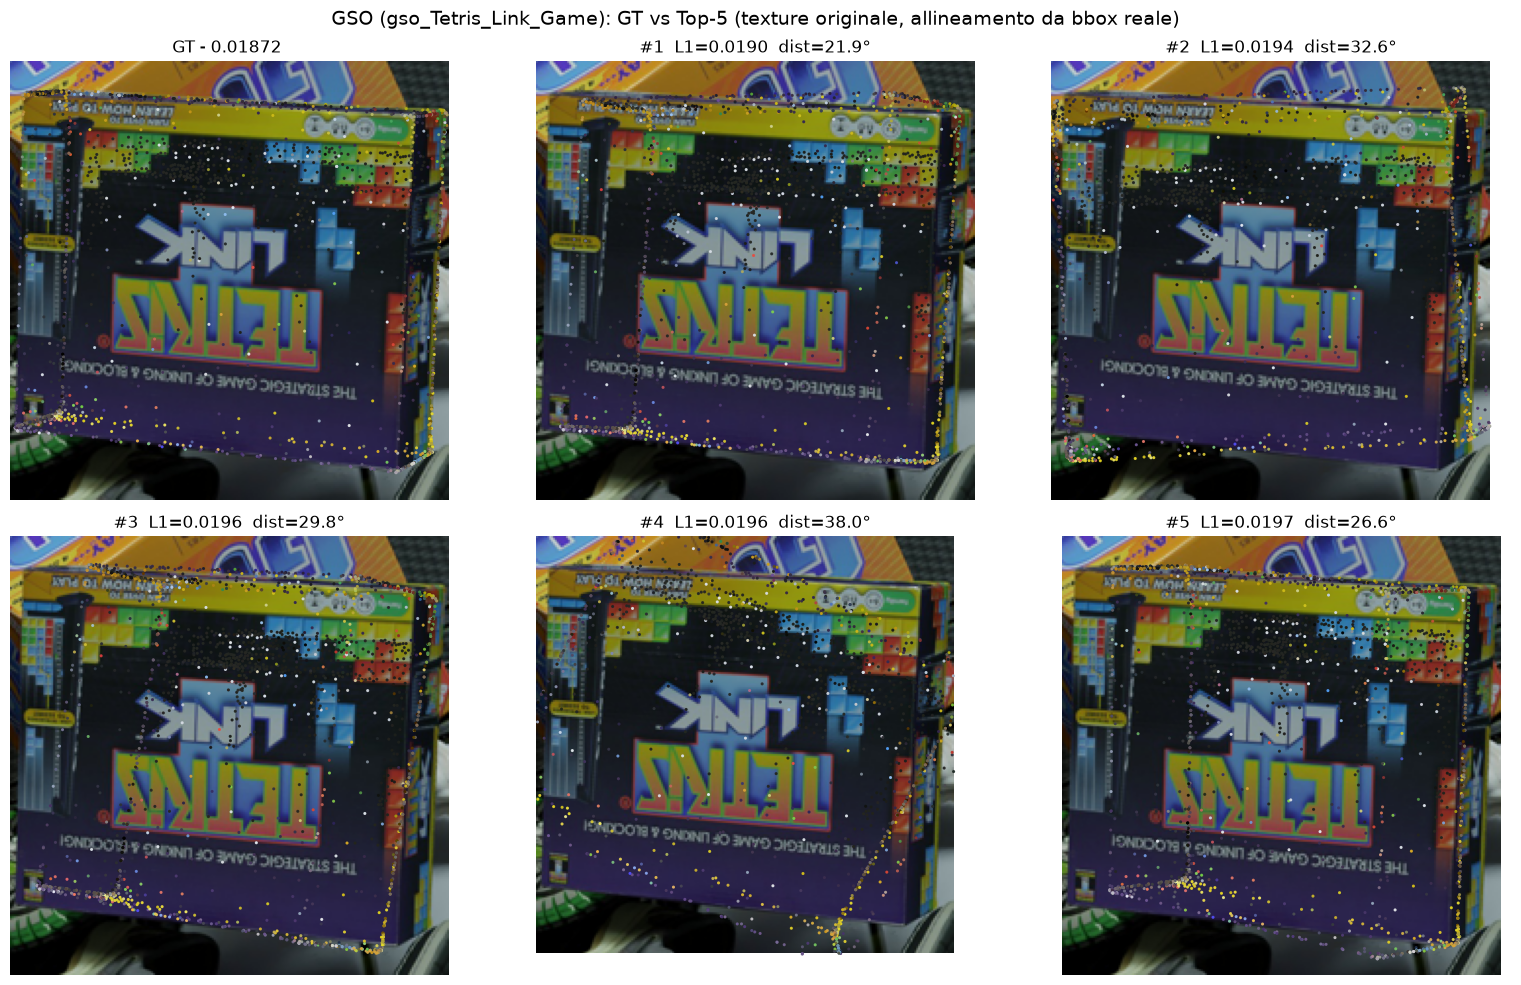

In [65]:
import os
import numpy as np
from PIL import Image
import trimesh
import matplotlib.pyplot as plt

# ============================================================
# 1. Carica ENTRAMBE le mesh: orig (texture) e bop-renderer (frame di riferimento)
# ============================================================

def load_gso_mesh(model_dir: str) -> trimesh.Trimesh:
    obj_path = os.path.join(model_dir, "meshes", "model.obj")
    loaded = trimesh.load(obj_path, process=False)
    def fix_texture(mesh):
        vis = mesh.visual
        if hasattr(vis, "material") and getattr(vis.material, "image", None) is None:
            tex_path = os.path.join(model_dir, "materials", "textures", "texture.png")
            if os.path.exists(tex_path):
                vis.material.image = Image.open(tex_path)
        return mesh
    if isinstance(loaded, trimesh.Scene):
        geoms = [fix_texture(g) for g in loaded.geometry.values()]
        mesh = trimesh.util.concatenate(geoms)
    else:
        mesh = fix_texture(loaded)
    return mesh

def load_gso_bop_mesh(model_dir: str) -> trimesh.Trimesh:
    ply_path = os.path.join(model_dir, "meshes", "model.ply")
    mesh = trimesh.load(ply_path, process=False)
    return mesh


gso_model_dir = f"/data/riccardop02/datasets/gso/{model_name.replace('gso_', '')}"
gso_bop_model_dir = f"/data/riccardop02/datasets/gso_MP/google_scanned_objects/models_bop-renderer_scale=0.1/{model_name.replace('gso_', '')}"

mesh_gso = load_gso_mesh(gso_model_dir)                       # con texture
mesh_gso_bop = load_gso_bop_mesh(gso_bop_model_dir)            # frame di riferimento (mm)
    
vertices_orig = np.array(mesh_gso.vertices)                    # metri
vertices_bop = np.array(mesh_gso_bop.vertices) / 1000.0        # mm -> metri

# ============================================================
# 2. Calcola la trasformazione ESATTA orig -> bop-frame, dai dati reali
#    (mappa il bounding box di orig dentro il bounding box di bop)
# ============================================================

bbox_min_orig, bbox_max_orig = vertices_orig.min(axis=0), vertices_orig.max(axis=0)
bbox_min_bop, bbox_max_bop = vertices_bop.min(axis=0), vertices_bop.max(axis=0)

bbox_center_orig = (bbox_min_orig + bbox_max_orig) / 2.0
bbox_center_bop  = (bbox_min_bop + bbox_max_bop) / 2.0

extent_orig = bbox_max_orig - bbox_min_orig
extent_bop  = bbox_max_bop - bbox_min_bop

scale_per_axis = extent_bop / extent_orig
scale = scale_per_axis.mean()   # dovrebbe essere quasi identica sui 3 assi (scala isotropa)

print("Scala per asse (dovrebbero combaciare, conferma scala isotropa):", scale_per_axis)
print("Scala usata:", scale)
print("Centro bop (target):", bbox_center_bop)

def align_orig_to_bop_frame(vertices_orig):
    return (vertices_orig - bbox_center_orig) * scale + bbox_center_bop

vertices_gso = align_orig_to_bop_frame(vertices_orig)

print("Estensione allineata:", vertices_gso.max(axis=0) - vertices_gso.min(axis=0))
print("Centro allineato:", (vertices_gso.min(axis=0) + vertices_gso.max(axis=0)) / 2.0)
print("(atteso: molto vicino a extent_bop e bbox_center_bop stampati sopra)")

# --- Colori dalla texture reale ---
mesh_gso_colored = mesh_gso.copy()
if hasattr(mesh_gso_colored.visual, "to_color"):
    mesh_gso_colored.visual = mesh_gso_colored.visual.to_color()
vertex_colors_gso = mesh_gso_colored.visual.vertex_colors[:, :3] / 255.0


# ============================================================
# 3. Proiezione GT + Top-5
# ============================================================

t_np_gso = batch['trans'][0].numpy().astype(np.float32)
K_np_gso = K_t.squeeze(0).cpu().numpy()

def project_points(vertices, R_mat, t_vec, K_mat):
    points_cam = (R_mat @ vertices.T) + t_vec.reshape(3, 1)
    points_img_h = K_mat @ points_cam
    return (points_img_h[:2, :] / points_img_h[2, :]).T

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()
h_bg, w_bg = bg_img_gso.shape[:2]

pts_gt = project_points(vertices_gso, rot_correct_np_gso, t_np_gso, K_np_gso)
valid_gt = (pts_gt[:,0]>=0)&(pts_gt[:,0]<w_bg)&(pts_gt[:,1]>=0)&(pts_gt[:,1]<h_bg)
axes[0].imshow(bg_img_gso)
axes[0].scatter(pts_gt[valid_gt,0], pts_gt[valid_gt,1], s=1.5, c=vertex_colors_gso[valid_gt], alpha=0.9)
axes[0].set_title(f"GT - {err_correct_gso.item():.5f} ")
axes[0].axis('off')

for rank in range(K_TOP):
    R_k = topk_rotations_gso[rank]
    dist_deg = rotation_geodesic_distance_deg(R_k, rot_correct_np_gso)
    pts_k = project_points(vertices_gso, R_k, t_np_gso, K_np_gso)
    valid_k = (pts_k[:,0]>=0)&(pts_k[:,0]<w_bg)&(pts_k[:,1]>=0)&(pts_k[:,1]<h_bg)
    ax = axes[rank+1]
    ax.imshow(bg_img_gso)
    ax.scatter(pts_k[valid_k,0], pts_k[valid_k,1], s=1.5, c=vertex_colors_gso[valid_k], alpha=0.9)
    ax.set_title(f"#{rank+1}  L1={topk_errs_gso[rank]:.4f}  dist={dist_deg:.1f}°")
    ax.axis('off')

plt.suptitle(f"GSO ({model_name}): GT vs Top-5 (texture originale, allineamento da bbox reale)", fontsize=14)
plt.tight_layout()
plt.show()

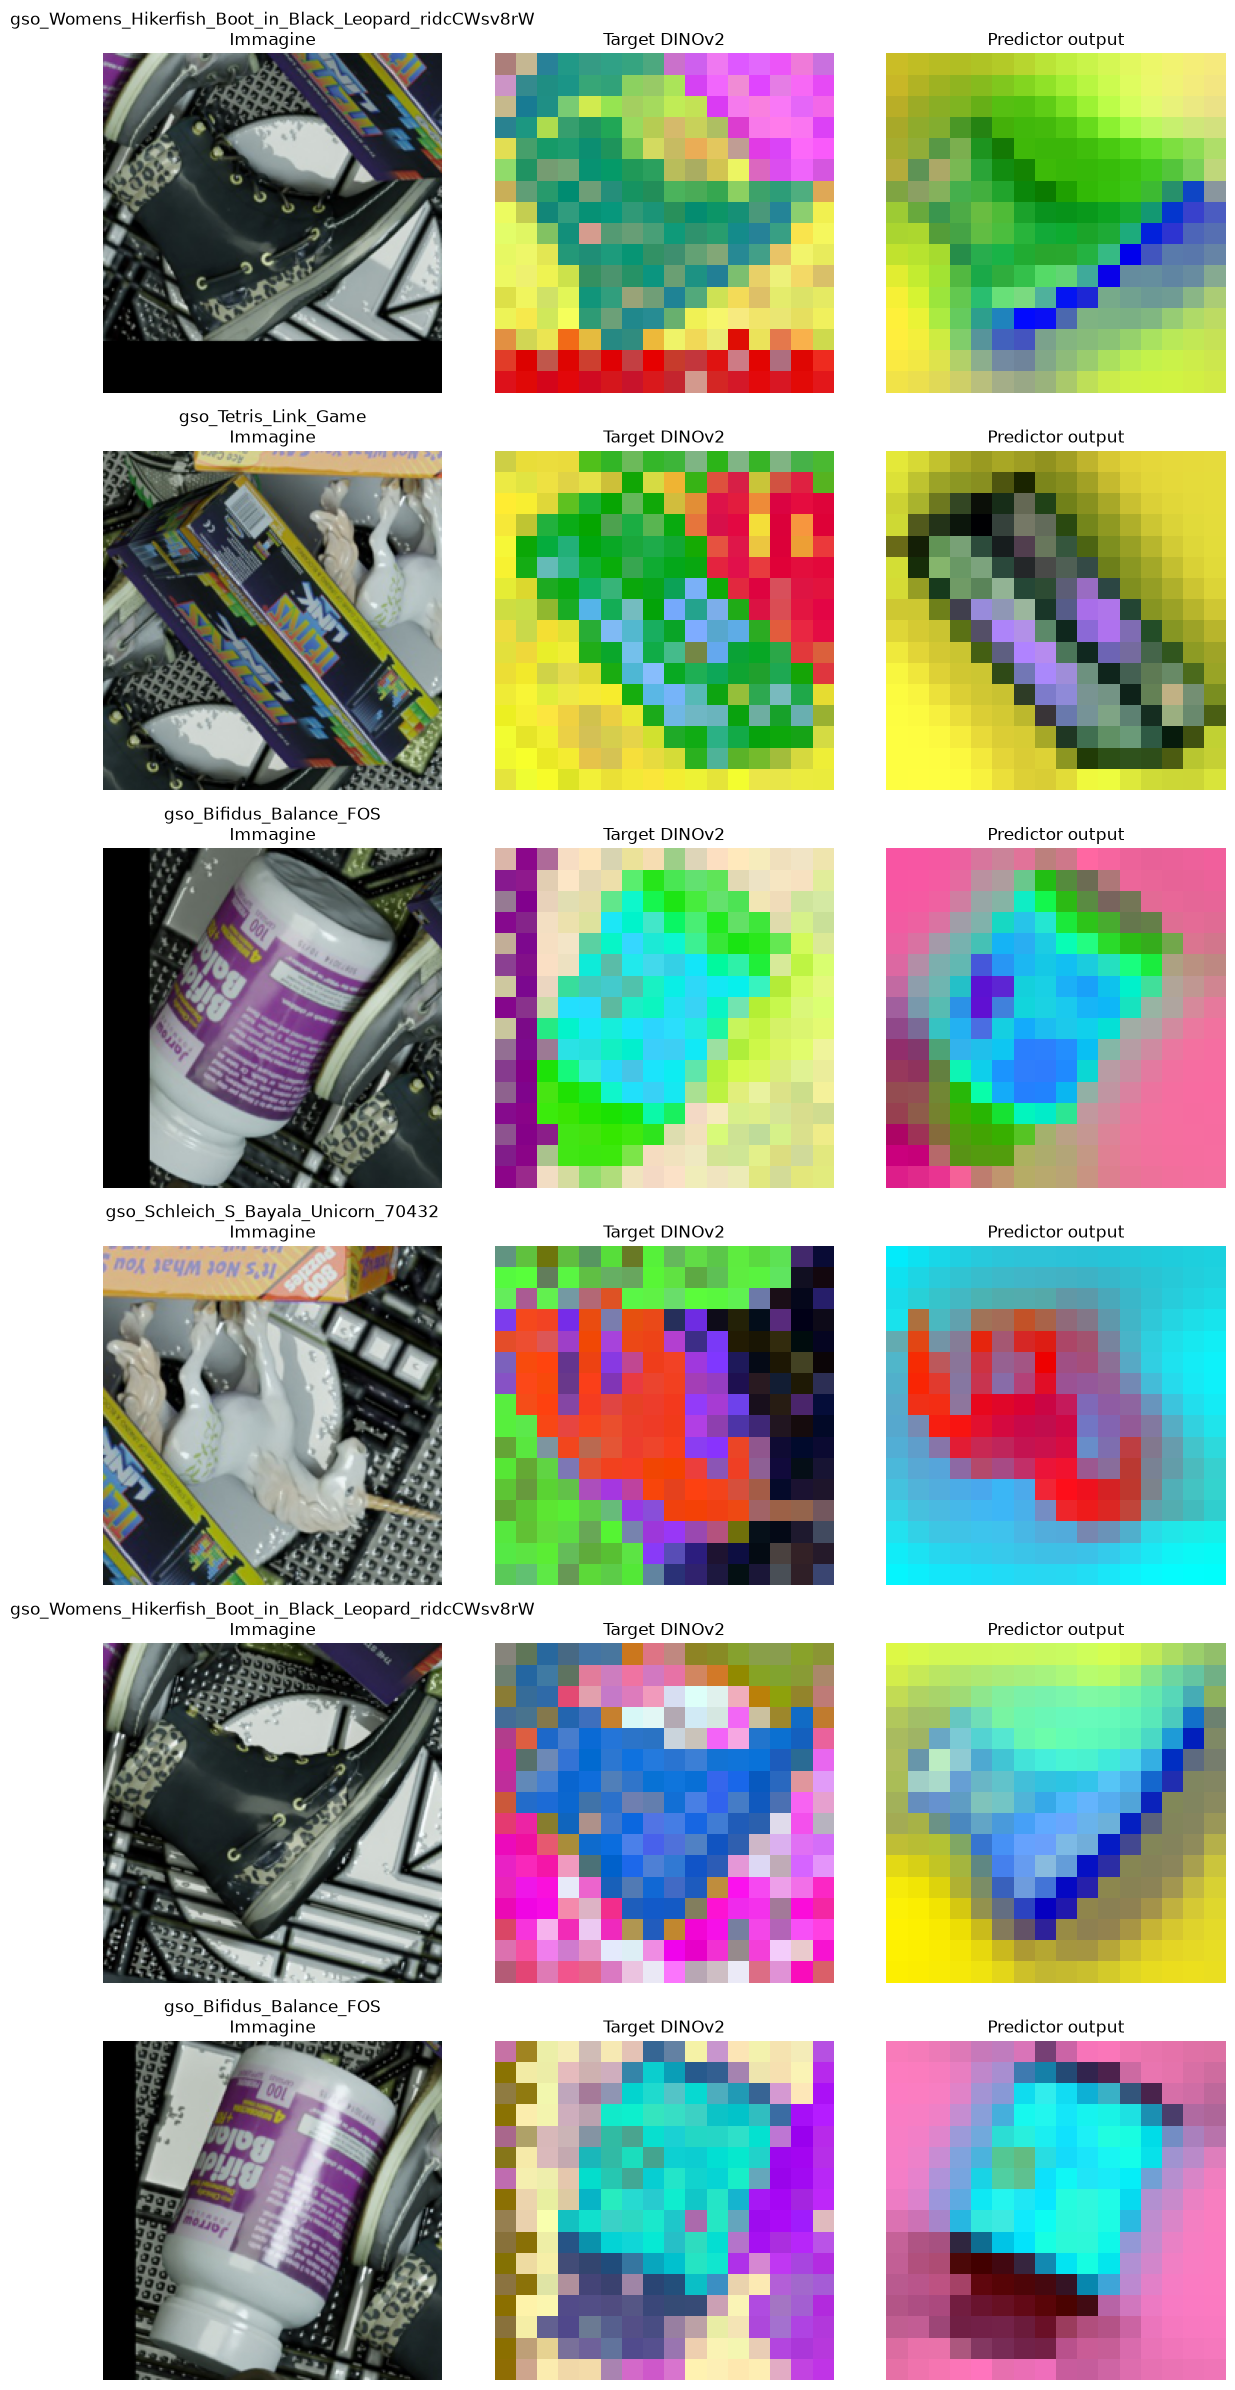

In [66]:
# Plotting for 3 object of the batch the image, the prediction of dinov2 and the the predictor output (the channel 768 should be shrinked by PCA)

# Qualitativi predictor: confronto mappe di embedding DINOv2 (target) vs Predictor
# PCA fittata sui token del TARGET, poi APPLICATA (stessa proiezione) al predictor

from sklearn.decomposition import PCA

N_OBJECTS = 6
GRID_SIZE = 16

fig, axes = plt.subplots(N_OBJECTS, 3, figsize=(12, 4 * N_OBJECTS))
if N_OBJECTS == 1:
    axes = axes[None, :]

for i in range(N_OBJECTS):
    # --- Prendi un nuovo sample dal dataloader ---
    batch = next(sample_iter)

    img_t = batch['image'].to(device)
    mask_t = batch['mask_tokens'].to(device)
    context_t = batch['context_3d'].to(device)
    centers_t = batch['center_3d'].to(device)
    rot_t = batch['rot_matrix'].to(device)
    K_t = batch['K'].to(device)
    model_name = batch['model_name'][0]

    # --- Immagine de-normalizzata per il plot (STD/MEAN già definiti in una cella precedente) ---
    img_denorm = (img_t * STD + MEAN).clamp(0, 1)
    bg_img = (img_denorm.squeeze(0).permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)

    # --- Target (DINOv2) e predizione del predictor con rotazione corretta (GT) ---
    ray_dirs_correct = generate_rays(K_t, rot_t)
    with torch.no_grad():
        target = encoder2d(img_t)                       # (1, 256, 768)
        pred = predictor(
            ray_queries=ray_dirs_correct,
            context_features=context_t,
            context_centers=centers_t,
            mask=mask_t
        )                                                 # (1, 256, 768)

    target_np = target.squeeze(0).cpu().numpy()           # (256, 768)
    pred_np = pred.squeeze(0).cpu().numpy()                # (256, 768)

    # --- PCA fittata SOLO sul target, applicata (transform) anche al predictor ---
    pca = PCA(n_components=3)
    target_pca = pca.fit_transform(target_np)              # (256, 3)
    pred_pca = pca.transform(pred_np)                      # (256, 3) -- stessa proiezione, riusata

    def to_rgb_map(pca_tokens, grid_size=GRID_SIZE):
        """Normalizza le componenti PCA in [0,1] e reshape in mappa (grid, grid, 3)."""
        vmin = pca_tokens.min(axis=0, keepdims=True)
        vmax = pca_tokens.max(axis=0, keepdims=True)
        norm = (pca_tokens - vmin) / (vmax - vmin + 1e-8)
        return norm.reshape(grid_size, grid_size, 3)

    target_map = to_rgb_map(target_pca)
    pred_map = to_rgb_map(pred_pca)

    # --- Plot: immagine | target DINOv2 (PCA) | predictor (PCA riusata) ---
    axes[i, 0].imshow(bg_img)
    axes[i, 0].set_title(f"{model_name}\nImmagine")
    axes[i, 0].axis('off')

    axes[i, 1].imshow(target_map)
    axes[i, 1].set_title("Target DINOv2")
    axes[i, 1].axis('off')

    axes[i, 2].imshow(pred_map)
    axes[i, 2].set_title("Predictor output")
    axes[i, 2].axis('off')

plt.tight_layout()
plt.show()